---
title: 'Solutions: Review of Neural Networks'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *Review of Neural Networks*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import pandas as pd

SEED = 2
torch.manual_seed(SEED)
np.random.seed(SEED)

# --- The chapter's regression data ---
n_samples = 30
def true_func(X): return np.cos(1.5 * np.pi * X)
np.random.seed(SEED)
X = np.sort(2*np.random.rand(n_samples)-1)
y = true_func(X) + np.random.randn(n_samples) * 0.1
X_plot = np.linspace(-1.5, 1.5, 100)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
X_train = X_train.reshape(-1,1).astype(np.float32)
y_train = y_train.reshape(-1,1).astype(np.float32)

# --- The chapter's curve ---
t = np.linspace(-1,1,100)
noise_level = 0.01
np.random.seed(SEED)
X_curve = np.vstack([np.sin(2*t),1*t**2,1*np.cos(5*t)]).T + noise_level*np.random.randn(len(t),3)

In [2]:
# The chapter's network classes
class Encoder(nn.Module):
    def __init__(self, num_input, num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        # I encourage you to modify the architecture here by adding more layers or changing activation functions, if you wish
        self.encode = nn.Sequential(
            nn.Linear(self.num_input, self.num_hidden),
            nn.ReLU(),
            #nn.Linear(self.num_hidden, self.num_hidden),
            #nn.ReLU(),
            nn.Linear(self.num_hidden, self.num_latent),
        )
        
    def forward(self, X):
        encoded = self.encode(X)
        return encoded
    
class Decoder(nn.Module):
    def __init__(self, num_input, num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        self.decode = nn.Sequential(
            nn.Linear(self.num_latent, self.num_hidden),
            nn.ReLU(),
            #nn.Linear(self.num_hidden, self.num_hidden),
            #nn.ReLU(),
            nn.Linear(self.num_hidden, self.num_input)
        )
        
    def forward(self, Z):
        decoded = self.decode(Z)
        return decoded
    
class AutoEncoder(nn.Module):
    def __init__(self, num_input,num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        self.encoder = Encoder(num_input  = self.num_input,
                               num_latent = self.num_latent,
                               num_hidden = self.num_hidden)
        self.decoder = Decoder(num_input  = self.num_input,
                               num_latent = self.num_latent,
                               num_hidden = self.num_hidden)
        
    def forward(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded, encoded  # <- return a tuple of two values
    
    def transform(self,X):
        '''Take X and encode to latent space'''
        return self.encoder(X)
    
    def inverse_transform(self,Z):
        '''Take Z and decode to X space'''
        return self.decoder(Z)


class _Combo(nn.Module):
    def forward(self, input):
        return self.model(input)

class LinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, out_features),
            activation
        )

class MLP(nn.Module):
    """Regular fully connected network generating features.

    Args:
        in_features: The number of input features.
        out_feature: The number of output features.
        layer_width: The widths of the hidden layers.
        combo: The layer combination to be stacked up.

    Shape:
        - Input: `(N, H_in)` where H_in = in_features.
        - Output: `(N, H_out)` where H_out = out_features.
    """
    def __init__(
        self, in_features: int, out_features:int, layer_width: list,
        combo = LinearCombo
        ):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.layer_width = list(layer_width)
        self.model = self._build_model(combo)

    def forward(self, input):
        return self.model(input)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        model.add_module(str(idx+1), nn.Linear(*self.layer_sizes[-1])) # type:ignore
        return model

    @property
    def layer_sizes(self):
        return list(zip([self.in_features] + self.layer_width,
        self.layer_width + [self.out_features]))


from torch.nn.utils.parametrizations import spectral_norm

class SNLinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            spectral_norm(nn.Linear(in_features, out_features)),
            activation
        )

class SNMLP(MLP):
    def __init__(
        self, in_features: int, out_features: int, layer_width: list,
        combo=SNLinearCombo):
        super().__init__(in_features, out_features, layer_width, combo)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        # Note here is the main difference: the last layer also has spectral normalization
        # This was not the case in the previous MLP definition
        model.add_module(str(idx+1), spectral_norm(nn.Linear(*self.layer_sizes[-1])))
        return model

In [3]:
# The helper and the faulty readings from the Exercise 2 cell of the chapter
# Two faulty sensor readings: copy the training targets and corrupt two of them
faulty_points = [3, 10]  # the readings at x = 0.010 and x = -0.559
y_train_faulty = y_train.copy()
y_train_faulty[faulty_points] = 3.0


def make_mlp(seed=SEED, activation=nn.ReLU, hidden_size=7, num_hidden_layers=3):
    """The chapter's deep network (1 -> 7 -> 7 -> 7 -> 7 -> 1) with fresh random weights."""
    torch.manual_seed(seed)
    layers = [nn.Linear(1, hidden_size), activation()]
    for _ in range(num_hidden_layers):
        layers.append(nn.Linear(hidden_size, hidden_size))
        layers.append(activation())
    layers.append(nn.Linear(hidden_size, 1))
    return nn.Sequential(*layers)

In [4]:
def train(net, inputs, targets, criterion=nn.MSELoss(), epochs=5000, learning_rate=0.05, extra_loss=None):
    """The chapter's training loop (Adam), with an optional extra term added to the loss."""
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    inputs, targets = torch.as_tensor(inputs), torch.as_tensor(targets)
    for epoch in range(epochs):
        outputs = net(inputs)
        loss = criterion(outputs, targets)
        if extra_loss is not None:
            loss = loss + extra_loss(net)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return net


def predict(net, x):
    with torch.no_grad():
        return net(torch.from_numpy(np.asarray(x, dtype=np.float32).reshape(-1, 1))).numpy().ravel()


x_fine = np.linspace(-1.5, 1.5, 601)

### Exercise 1: Count the parameters

In [5]:
def count_parameters(module):
    return sum(p.numel() for p in module.parameters())


autoencoder = AutoEncoder(3, 3, 5)
print("AutoEncoder(3, 3, 5):")
for name, layer in autoencoder.named_modules():
    if isinstance(layer, nn.Linear):
        print(f"  {name:18s} {layer.in_features} -> {layer.out_features}: "
              f"{layer.in_features} x {layer.out_features} + {layer.out_features} = {count_parameters(layer)}")
print(f"  total: {count_parameters(autoencoder)}")

ambient_dim, width = 3, 48
lv_encoder = MLP(ambient_dim, ambient_dim, [width] * 4)
print("\nMLP(3, 3, [48] * 4):")
for name, layer in lv_encoder.named_modules():
    if isinstance(layer, nn.Linear):
        print(f"  {name:18s} {layer.in_features} -> {layer.out_features}: {count_parameters(layer)}")
print(f"  total: {count_parameters(lv_encoder)}")
print(f"\nSNMLP(3, 3, [48] * 4) decoder, for comparison: {count_parameters(SNMLP(ambient_dim, ambient_dim, [width] * 4))}")

AutoEncoder(3, 3, 5):
  encoder.encode.0   3 -> 5: 3 x 5 + 5 = 20
  encoder.encode.2   5 -> 3: 5 x 3 + 3 = 18
  decoder.decode.0   3 -> 5: 3 x 5 + 5 = 20
  decoder.decode.2   5 -> 3: 5 x 3 + 3 = 18
  total: 76

MLP(3, 3, [48] * 4):
  model.0.model.0    3 -> 48: 192
  model.1.model.0    48 -> 48: 2352
  model.2.model.0    48 -> 48: 2352
  model.3.model.0    48 -> 48: 2352
  model.4            48 -> 3: 147
  total: 7395

SNMLP(3, 3, [48] * 4) decoder, for comparison: 7395


**(a)** 76 parameters. Each `nn.Linear(n_in, n_out)` has `n_in * n_out` weights and `n_out` biases:

| Layer | Shape | Weights + biases | Parameters |
|---|---|---|---|
| encoder, first `Linear` | 3 to 5 | 15 + 5 | 20 |
| encoder, second `Linear` | 5 to 3 | 15 + 3 | 18 |
| decoder, first `Linear` | 3 to 5 | 15 + 5 | 20 |
| decoder, second `Linear` | 5 to 3 | 15 + 3 | 18 |
| total | all four layers | 60 + 16 | 76 |

The `nn.ReLU()` layers add nothing because $\max(0, x)$ is a fixed function. It has no weights to learn, so it has no parameters.

**(b)** 7395 parameters: $3 \cdot 48 + 48 = 192$ for the input layer, $48 \cdot 48 + 48 = 2352$ for each of the three hidden-to-hidden layers, and $48 \cdot 3 + 3 = 147$ for the output layer, so $192 + 3 \cdot 2352 + 147 = 7395$. The three $48 \times 48$ layers hold 7056 of them, about 95%. The number of weights in a layer is the product of the widths on either side, and $48 \cdot 48 = 2304$ is much larger than $3 \cdot 48 = 144$. The `LeakyReLU` activations again add nothing. The spectrally normalized decoder `SNMLP(3, 3, [48] * 4)` also has 7395 trainable parameters, because spectral normalization stores its power-iteration vectors as buffers, not as parameters.

### Exercise 2: Change the loss

MSE loss: prediction at the faulty readings [ 1.9 -0.2], mean absolute error on the other 16 readings 0.292
L1 loss: prediction at the faulty readings [ 1.01 -0.57], mean absolute error on the other 16 readings 0.061


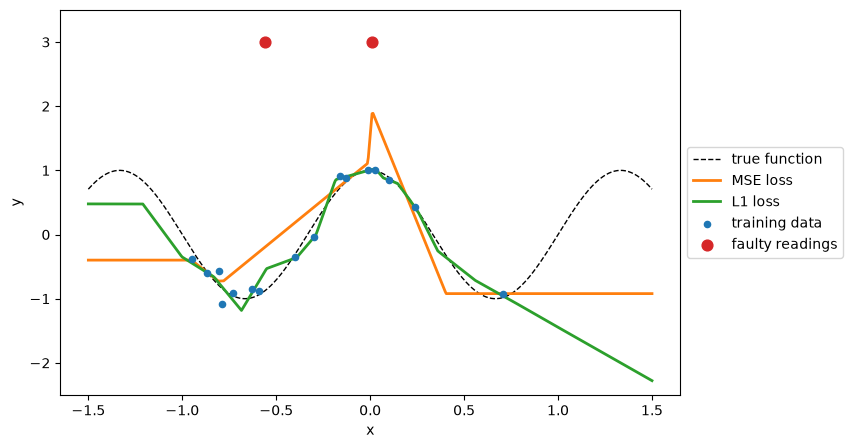

In [6]:
fits = {}
for name, criterion in [("MSE loss", nn.MSELoss()), ("L1 loss", nn.L1Loss())]:
    fits[name] = train(make_mlp(), X_train, y_train_faulty, criterion=criterion)

good = np.setdiff1d(np.arange(len(X_train)), faulty_points)
for name, net in fits.items():
    at_faulty = predict(net, X_train[faulty_points])
    error_good = np.mean(np.abs(predict(net, X_train[good]) - y_train[good, 0]))
    print(f"{name}: prediction at the faulty readings {np.round(at_faulty, 2)}, "
          f"mean absolute error on the other 16 readings {error_good:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(x_fine, true_func(x_fine), "k--", lw=1, label="true function")
for (name, net), color in zip(fits.items(), ["tab:orange", "tab:green"]):
    plt.plot(x_fine, predict(net, x_fine), color=color, lw=2, label=name)
plt.scatter(X_train, y_train_faulty, c="tab:blue", s=20, zorder=3, label="training data")
plt.scatter(X_train[faulty_points], y_train_faulty[faulty_points], c="tab:red", s=60, zorder=3, label="faulty readings")
plt.ylim(-2.5, 3.5)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

without the symmetry term: largest |f(x) - f(-x)| 3.15, RMS error outside [-1, 1] 1.85, RMS error on (0.25, 1] 0.47
with the symmetry term: largest |f(x) - f(-x)| 0.06, RMS error outside [-1, 1] 0.31, RMS error on (0.25, 1] 0.07


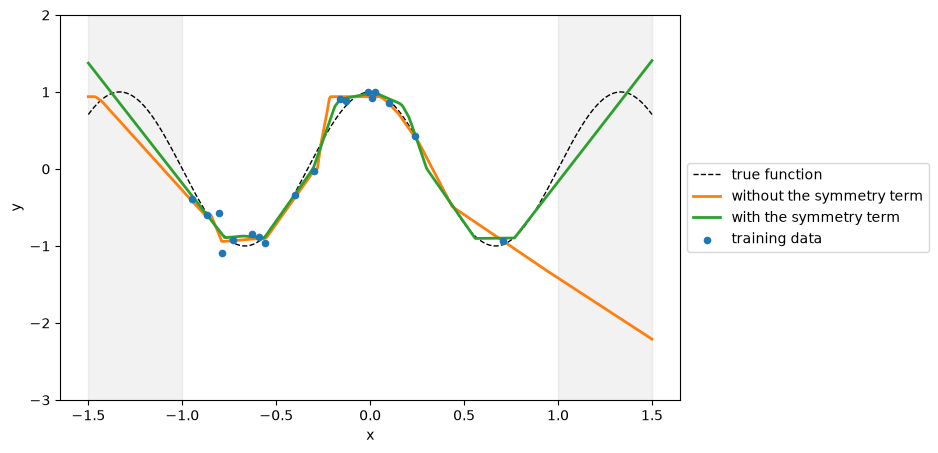

In [7]:
# (b) Symmetry penalty on extra, unlabeled inputs, trained on the clean data
x_extra = torch.linspace(0, 1.5, 31).reshape(-1, 1)
symmetry_loss = lambda net: torch.mean((net(x_extra) - net(-x_extra))**2)
plain = train(make_mlp(), X_train, y_train)
symmetric = train(make_mlp(), X_train, y_train, extra_loss=symmetry_loss)

outside = np.abs(x_fine) > 1
sparse = (x_fine > 0.25) & (x_fine <= 1)
for name, net in [("without the symmetry term", plain), ("with the symmetry term", symmetric)]:
    p = predict(net, x_fine)
    print(f"{name}: largest |f(x) - f(-x)| {np.max(np.abs(p - p[::-1])):.2f}, "
          f"RMS error outside [-1, 1] {np.sqrt(np.mean((p[outside] - true_func(x_fine[outside]))**2)):.2f}, "
          f"RMS error on (0.25, 1] {np.sqrt(np.mean((p[sparse] - true_func(x_fine[sparse]))**2)):.2f}")

plt.figure(figsize=(8, 5))
plt.plot(x_fine, true_func(x_fine), "k--", lw=1, label="true function")
plt.plot(x_fine, predict(plain, x_fine), color="tab:orange", lw=2, label="without the symmetry term")
plt.plot(x_fine, predict(symmetric, x_fine), color="tab:green", lw=2, label="with the symmetry term")
plt.scatter(X_train, y_train, c="tab:blue", s=20, zorder=3, label="training data")
plt.axvspan(-1.5, -1, color="gray", alpha=0.1)
plt.axvspan(1, 1.5, color="gray", alpha=0.1)
plt.ylim(-3, 2)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

**(a)** With the squared loss, the fit moves toward both faulty readings. It predicts 1.9 at $x = 0.010$, where the clean data are about 1, and $-0.2$ at $x = -0.559$, where the nearby readings are about $-0.9$. It also fits the good readings worse: its mean absolute error on the other 16 readings is 0.292. With the absolute loss, the fit stays close to the clean data. It predicts 1.01 and $-0.57$ at the two faulty readings, and its mean absolute error on the good readings is 0.061.

The difference comes from the gradient of each loss with respect to the residual $r = f(x) - y$. For the squared loss $r^2$, the gradient is $2r$, so it grows with the residual. A reading that is off by 2 to 4 contributes a gradient 20 to 40 times larger than a good reading that is off by 0.1, so the two faulty readings can outweigh the other 16. For the absolute loss $|r|$, the gradient is $\pm 1$ for every reading, whatever the size of the residual, so two readings cannot outweigh sixteen. Minimizing the squared loss estimates a mean, which is sensitive to outliers. Minimizing the absolute loss estimates a median, which is not.

**(b)** Without the symmetry term, the fit is far from symmetric: the largest difference $|f(x) - f(-x)|$ on $[-1.5, 1.5]$ is 3.15. Its RMS (root mean square) error against the true function is 1.85 outside $[-1, 1]$ and 0.47 on $(0.25, 1]$, where there is only one training reading. With the symmetry term, the largest difference drops to 0.06, the RMS error outside $[-1, 1]$ to 0.31, and the error on $(0.25, 1]$ to 0.07.

The term does not use measured outputs. It compares the network's prediction at $x$ with its prediction at $-x$. The training data are dense on the left half of the input range and sparse on the right half, so the term transfers information from the left half to the right half. Outside $[-1, 1]$ there are no data on either side, so the term only makes the two extrapolations equal. Here that brings them closer to the true function, but it does not make extrapolation reliable in general.

### Exercise 3: Match the activation

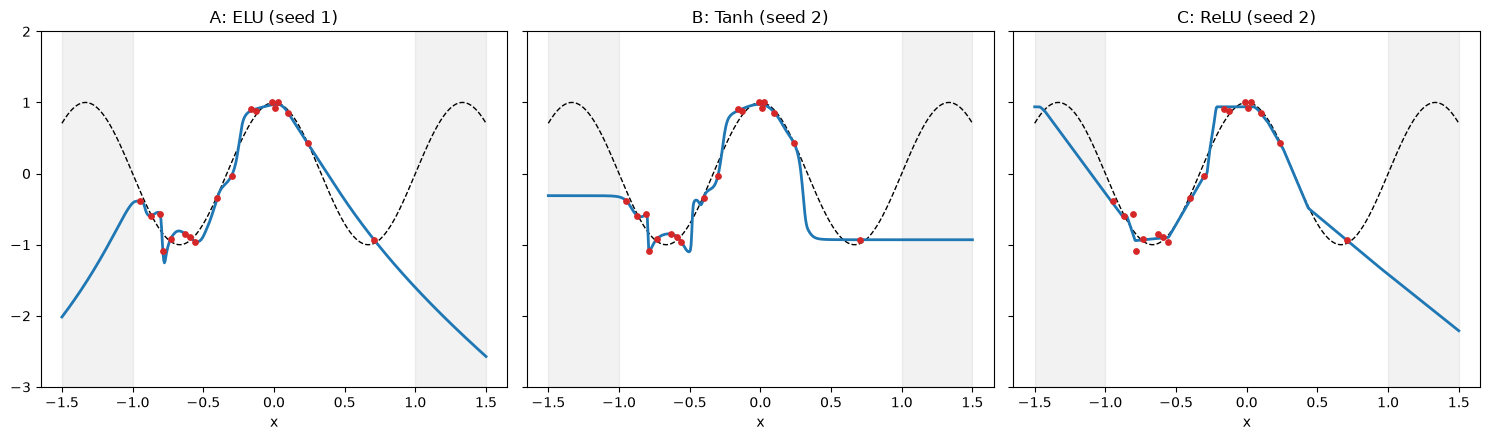

ELU, seed 2: slope of the fit over [1.25, 1.5] = 0.00


In [8]:
# The three fits of the exercise, now labeled (same activations and seeds as the hidden figure cell)
panels = {"A: ELU (seed 1)": (nn.ELU, 1), "B: Tanh (seed 2)": (nn.Tanh, 2), "C: ReLU (seed 2)": (nn.ReLU, 2)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (label, (activation, seed)) in zip(axes, panels.items()):
    net = train(make_mlp(seed=seed, activation=activation), X_train, y_train)
    ax.plot(x_fine, true_func(x_fine), "k--", lw=1)
    ax.plot(x_fine, predict(net, x_fine), "tab:blue", lw=2)
    ax.scatter(X_train, y_train, c="tab:red", s=15, zorder=3)
    ax.axvspan(-1.5, -1, color="gray", alpha=0.1)
    ax.axvspan(1, 1.5, color="gray", alpha=0.1)
    ax.set_title(label)
    ax.set_xlabel("x")
    ax.set_ylim(-3, 2)
plt.tight_layout()
plt.show()

# The ELU network with the chapter's seed instead: slope of the fit at the right end
elu_seed2 = predict(train(make_mlp(seed=2, activation=nn.ELU), X_train, y_train), x_fine)
print(f"ELU, seed 2: slope of the fit over [1.25, 1.5] = {(elu_seed2[-1] - elu_seed2[-51]) / 0.25:.2f}")

In [9]:
# (d) The ReLU network with ten seeds: training error, how much the fit varies over [-1.5, 1.5], and how many
# units in each hidden layer are active (output > 0) for at least one training input
def active_units(net, inputs):
    counts = []
    h = torch.from_numpy(inputs)
    with torch.no_grad():
        for layer in net:
            h = layer(h)
            if isinstance(layer, nn.ReLU):
                counts.append(int((h > 0).any(dim=0).sum()))
    return counts


for seed in range(10):
    net = train(make_mlp(seed=seed), X_train, y_train)
    mse = np.mean((predict(net, X_train) - y_train.ravel())**2)
    p = predict(net, x_fine)
    print(f"seed {seed}: training MSE {mse:.4f}, range of the fit {p.max() - p.min():.2f}, "
          f"active units per hidden layer {active_units(net, X_train)}")

seed 0: training MSE 0.6379, range of the fit 0.00, active units per hidden layer [4, 4, 1, 0]
seed 1: training MSE 0.0124, range of the fit 1.93, active units per hidden layer [5, 3, 3, 2]
seed 2: training MSE 0.0066, range of the fit 3.15, active units per hidden layer [4, 3, 3, 3]
seed 3: training MSE 0.0233, range of the fit 2.40, active units per hidden layer [2, 3, 3, 3]
seed 4: training MSE 0.0066, range of the fit 3.86, active units per hidden layer [6, 4, 2, 2]
seed 5: training MSE 0.6379, range of the fit 0.00, active units per hidden layer [5, 4, 4, 0]
seed 6: training MSE 0.3754, range of the fit 1.15, active units per hidden layer [4, 2, 2, 3]
seed 7: training MSE 0.1792, range of the fit 1.69, active units per hidden layer [4, 2, 2, 2]
seed 8: training MSE 0.0252, range of the fit 1.77, active units per hidden layer [3, 2, 3, 1]
seed 9: training MSE 0.0062, range of the fit 1.98, active units per hidden layer [4, 4, 4, 3]


**(a)** A is ELU, B is Tanh, and C is ReLU.

| Fit | Activation | How to recognize it |
|---|---|---|
| A | ELU | Smooth everywhere, and straight lines outside the data. ELU is linear for positive inputs and smooth around zero. |
| B | Tanh | Smooth, and flat outside the data on both sides. Tanh approaches $\pm 1$ for large inputs, so far from the data every unit outputs a constant. |
| C | ReLU | Straight segments with sharp corners, and straight lines outside the data. ReLU is piecewise linear, and sums and compositions of piecewise linear functions are piecewise linear. |

**(b)** Inside $[-1, 1]$, the loss keeps all three networks close to the training points, so the fits look similar there. Outside, no data constrain the fit. As $|x|$ grows, the inputs to the first-layer units grow linearly in $x$, so each unit's output is set by its activation function at large inputs: linear for ReLU, linear for ELU on the positive side and constant on the negative side, and constant for Tanh. The fit outside the data is a combination of these limits.

**(c)** With the chapter's `SEED`, setting `activation = nn.Tanh` or `nn.ReLU` reproduces fits B and C exactly, because the figure used the same seed, network, and training loop. Fit A used seed 1, because with seed 2 the ELU fit is flat on the right (slope 0.00 over $[1.25, 1.5]$). ELU approaches $-1$ for large negative inputs, so an ELU network can also be flat on one side. With a different seed, the positions of the corners, the slopes, and the values outside the data change, because they depend on the random initial weights. The type of curve stays the same: corners for ReLU, flat smooth tails for Tanh, and straight smooth tails for ELU.

**(d)** Of the ten seeds, seeds 0 and 5 give a flat line: the training MSE is 0.638 and the fit varies by 0.00 over $[-1.5, 1.5]$. In both runs, every one of the 7 ReLU units in the last hidden layer outputs 0 for every training input (0 active units in the table). A ReLU unit whose input is negative for all training inputs outputs 0 and has gradient 0, so gradient descent never changes its incoming weights again. When all units in a layer are in this state, the network's output equals the bias of the output layer, which is a constant, and no gradient reaches the earlier layers. Training can then only move that constant to the mean of the data. Seeds 6 and 7 fit poorly (training MSE 0.375 and 0.179) and have only 2 active units left in some layers. With only 7 units per layer and a learning rate of 0.05, a few early updates can make the inputs to all units of a layer negative. Tanh and ELU have a nonzero gradient for every input, so this cannot happen with them.

### Exercise 4: Three ways to penalize volume

::: {.callout-note collapse="true"}
### Code that generated the precomputed runs for Exercise 4
Each run was a separate process with one CPU thread. The four runs were collected into the CSV file `review_neural_networks_lv_penalties.csv` in the `data` folder.

```python
"""Precompute the least-volume runs read by Exercise 4 of the chapter Review of Neural Networks.

Each run trains the chapter's least-volume autoencoder exactly as the chapter does (seed 2, Adam with
learning rate 1e-3, 20000 steps, lambda = 0.01), but with one of four volume penalties. One process
is one run, so the runs can go in parallel (each process uses one CPU thread).

Usage: python precompute_lv_cold.py <outdir> <penalty>     penalty in {none, product, arithmetic, geometric}

Every 100 steps the run logs the sorted latent standard deviations, the gradient of the weighted
penalty with respect to each of them, and the reconstruction MSE, to <outdir>/<penalty>.json.
"""
import json
import sys

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import spectral_norm

torch.set_num_threads(1)

# ---- The chapter's classes -----------------------------------------------------------
class _Combo(nn.Module):
    def forward(self, input):
        return self.model(input)

class LinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, out_features),
            activation
        )

class MLP(nn.Module):
    def __init__(
        self, in_features: int, out_features:int, layer_width: list,
        combo = LinearCombo
        ):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.layer_width = list(layer_width)
        self.model = self._build_model(combo)

    def forward(self, input):
        return self.model(input)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        model.add_module(str(idx+1), nn.Linear(*self.layer_sizes[-1])) # type:ignore
        return model

    @property
    def layer_sizes(self):
        return list(zip([self.in_features] + self.layer_width,
        self.layer_width + [self.out_features]))

class SNLinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            spectral_norm(nn.Linear(in_features, out_features)),
            activation
        )

class SNMLP(MLP):
    def __init__(
        self, in_features: int, out_features: int, layer_width: list,
        combo=SNLinearCombo):
        super().__init__(in_features, out_features, layer_width, combo)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        model.add_module(str(idx+1), spectral_norm(nn.Linear(*self.layer_sizes[-1])))
        return model


# ---- The chapter's data and settings ------------------------------------------------------------
SEED = 2
t = np.linspace(-1, 1, 100)
np.random.seed(SEED)
X = np.vstack([np.sin(2*t), 1*t**2, 1*np.cos(5*t)]).T + 0.01*np.random.randn(len(t), 3)
X_torch = torch.from_numpy(X).float()
η, λ = 0.01, 0.01


def penalty(std, kind):
    if kind == "geometric":
        return torch.exp(torch.log(std + η).mean())
    if kind == "product":
        return torch.prod(std)
    if kind == "arithmetic":
        return std.mean()
    return torch.zeros(())


def main():
    outdir, kind = sys.argv[1], sys.argv[2]
    ambient_dim = X.shape[1]
    width = ambient_dim * 16
    torch.manual_seed(SEED)
    encoder = MLP(ambient_dim, ambient_dim, [width] * 4)
    decoder = SNMLP(ambient_dim, ambient_dim, [width] * 4)
    opt = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-3)
    log = {"step": [], "std": [], "grad": [], "rec": []}
    for i in range(20000):
        opt.zero_grad()
        z = encoder(X_torch)
        std = z.std(0)
        std.retain_grad()
        rec_loss = F.mse_loss(decoder(z), X_torch)
        loss = rec_loss + λ * penalty(std, kind)
        loss.backward()
        if i % 100 == 0 or i == 19999:
            # std enters the loss only through the penalty, so std.grad = lambda * dP/dsigma
            grad = std.grad if std.grad is not None else torch.zeros_like(std)
            order = torch.argsort(std.detach(), descending=True)
            log["step"].append(i)
            log["std"].append(std.detach()[order].tolist())
            log["grad"].append(grad[order].tolist())
            log["rec"].append(rec_loss.item())
        opt.step()
    json.dump(log, open(f"{outdir}/{kind}.json", "w"))
    print(kind, "std", np.round(log["std"][-1], 4), "rec", f"{log['rec'][-1]:.2e}", flush=True)


if __name__ == "__main__":
    main()
```
:::

In [10]:
def geometric_volume(std, eta=0.01):
    """The chapter's least-volume penalty: the geometric mean of the (shifted) standard deviations."""
    return torch.exp(torch.log(std + eta).mean())


def naive_volume(std):
    """The product of the standard deviations."""
    return torch.prod(std)


def mean_std(std):
    """The arithmetic mean of the standard deviations."""
    return torch.mean(std)


def compare_penalties(penalties, std_values=((2.0, 1.5, 0.01), (2.0, 1.5, 0.0))):
    """Print each penalty's value and its gradient with respect to each standard deviation."""
    for values in std_values:
        print(f"std = {values}")
        for penalty in penalties:
            std = torch.tensor(values, requires_grad=True)
            value = penalty(std)
            value.backward()
            print(f"  {penalty.__name__:>16}: value {value.item():.4f}, gradient {np.round(std.grad.numpy(), 4)}")


compare_penalties([geometric_volume, naive_volume, mean_std])

std = (2.0, 1.5, 0.01)
  geometric_volume: value 0.3930, gradient [0.0652 0.0868 6.5501]
      naive_volume: value 0.0300, gradient [0.015 0.02  3.   ]
          mean_std: value 1.1700, gradient [0.3333 0.3333 0.3333]
std = (2.0, 1.5, 0.0)
  geometric_volume: value 0.3119, gradient [ 0.0517  0.0689 10.3977]
      naive_volume: value 0.0000, gradient [0. 0. 3.]
          mean_std: value 1.1667, gradient [0.3333 0.3333 0.3333]


In [11]:
curves = pd.read_csv("../data/review_neural_networks_lv_penalties.csv")
late = curves[curves["step"] >= 18000]  # the last 2000 steps
summary = late.groupby("penalty").agg(
    std_1=("std_1", "mean"), std_2=("std_2", "mean"), std_3=("std_3", "mean"),
    push_1=("grad_1", "mean"), push_2=("grad_2", "mean"), push_3=("grad_3", "mean"),
    rec_mse=("rec_mse", lambda r: np.exp(np.log(r).mean())))  # geometric mean, since the MSE is noisy
summary = summary.loc[["product", "arithmetic", "geometric", "none"]]
print("Averages over the last 2000 steps:")
print(summary.to_string(float_format=lambda v: f"{v:.2e}"))

start = curves[curves["step"] == 0].set_index("penalty").loc[["product", "arithmetic", "geometric"]]
print("\nAt the start of training (step 0):")
print(start[["std_1", "std_2", "std_3", "grad_1", "grad_2", "grad_3"]].to_string(float_format=lambda v: f"{v:.2e}"))

Averages over the last 2000 steps:
              std_1    std_2    std_3   push_1   push_2   push_3  rec_mse
penalty                                                                  
product    3.05e+00 4.11e-01 2.36e-03 9.67e-06 7.18e-05 1.25e-02 3.17e-05
arithmetic 8.33e-01 7.19e-01 3.05e-01 3.33e-03 3.33e-03 3.33e-03 4.04e-05
geometric  3.14e+01 8.37e-03 2.79e-03 2.05e-05 3.61e-02 5.08e-02 1.37e-03
none       9.42e+00 7.67e+00 5.22e+00 0.00e+00 0.00e+00 0.00e+00 2.37e-05

At the start of training (step 0):
              std_1    std_2    std_3   grad_1   grad_2   grad_3
penalty                                                         
product    1.09e-02 5.96e-03 4.78e-03 2.85e-07 5.21e-07 6.50e-07
arithmetic 1.09e-02 5.96e-03 4.78e-03 3.33e-03 3.33e-03 3.33e-03
geometric  1.09e-02 5.96e-03 4.78e-03 2.72e-03 3.55e-03 3.84e-03


**(a)** The values and gradients printed above are:

| Penalty | Value for $\sigma = (2, 1.5, 0.01)$ | Gradient | Value for $\sigma = (2, 1.5, 0)$ | Gradient |
|---|---|---|---|---|
| geometric mean | 0.393 | (0.065, 0.087, 6.55) | 0.312 | (0.052, 0.069, 10.4) |
| product | 0.030 | (0.015, 0.020, 3.0) | 0 | (0, 0, 3.0) |
| arithmetic mean | 1.170 | (0.333, 0.333, 0.333) | 1.167 | (0.333, 0.333, 0.333) |

The geometric mean's gradient is about 100 times larger for the smallest dimension than for the two large ones. The product's gradient is also largest for the smallest dimension, and very small for the other two. The arithmetic mean has the same gradient, 1/3, for all three. Once $\sigma_3 = 0$, the product's gradient for the first two dimensions is zero, because $\partial(\sigma_1 \sigma_2 \sigma_3)/\partial \sigma_1 = \sigma_2 \sigma_3 = 0$. The product is then zero whatever $\sigma_1$ and $\sigma_2$ are. The geometric mean's gradients for $\sigma_1$ and $\sigma_2$ stay nonzero, because $\eta$ keeps every factor $\sigma_i + \eta$ above zero.

::: {.callout-note collapse="true"}
### Derivation of the three gradients
With $d$ dimensions and $G = \left(\prod_{j=1}^{d} (\sigma_j + \eta)\right)^{1/d} = \exp\left(\frac{1}{d}\sum_{j=1}^{d} \log(\sigma_j + \eta)\right)$,

$$
\frac{\partial G}{\partial \sigma_i} = \frac{G}{d\,(\sigma_i + \eta)}, \qquad
\frac{\partial}{\partial \sigma_i} \prod_{j=1}^{d} \sigma_j = \prod_{j \neq i} \sigma_j, \qquad
\frac{\partial}{\partial \sigma_i} \frac{1}{d}\sum_{j=1}^{d} \sigma_j = \frac{1}{d}.
$$

So the geometric mean's gradient for dimension $i$ is inversely proportional to $\sigma_i + \eta$: small for large dimensions and large for small ones. The product's gradient for dimension $i$ is the product of the other standard deviations, and the arithmetic mean's gradient is the same constant $1/d$ for every dimension.
:::

**(b)** Averaged over the last 2000 steps, the geometric mean keeps one dimension: the standard deviations are 31, 0.008, and 0.003. The product keeps two: 3.0, 0.41, and 0.002. The arithmetic mean keeps all three: 0.83, 0.72, and 0.31. Without a penalty they are 9.4, 7.7, and 5.2.

The product removes the third dimension and then stops, as (a) predicts. With $\sigma_3 \approx 0.002$, its gradient on $\sigma_2$ is $\lambda \sigma_1 \sigma_3 \approx 7 \times 10^{-5}$, so there is almost no pressure left to remove the second dimension. The geometric mean's gradient on a small dimension is $\lambda G / (d\,(\sigma_i + \eta))$, which does not depend on the other dimensions being nonzero. It keeps a gradient of 0.036 and 0.051 on its two small dimensions, so it removes the second dimension too. The arithmetic mean has the same gradient, $\lambda/3 = 3.3 \times 10^{-3}$, on every dimension, so the smallest dimension gets no extra pressure. It shrinks all three dimensions, but the reconstruction still uses all three, and none reaches zero.

**(c)** The product of three standard deviations of about 0.01 is about $10^{-6}$, and its gradient on each of them is the product of the other two, between $3 \times 10^{-5}$ and $7 \times 10^{-5}$. With $\lambda = 0.01$, that gives the gradients of $3 \times 10^{-7}$ to $6 \times 10^{-7}$ printed above, against $2.7 \times 10^{-3}$ to $3.8 \times 10^{-3}$ for the geometric mean and $3.3 \times 10^{-3}$ for the arithmetic mean. The product grows with the cube of the scale of the code: dividing all standard deviations by 10 divides the product by 1000 and its gradients by 100. The geometric and arithmetic means grow linearly with the scale, so their gradients do not depend on it. At the start of training the product therefore has almost no effect. Its gradient on one dimension grows only as the other dimensions grow: in the figure, the gradient on the third dimension reaches about 0.06 within the first few hundred steps, once the first two dimensions have grown. With more latent dimensions this gets worse: with $d$ dimensions the product grows with the $d$-th power of the scale.

**(d)** The reconstruction MSE over the last 2000 steps is $1.4 \times 10^{-3}$ for the geometric mean, against $3.2 \times 10^{-5}$ for the product, $4.0 \times 10^{-5}$ for the arithmetic mean, and $2.4 \times 10^{-5}$ without a penalty. The geometric mean measures each dimension by its relative size, so shrinking the second dimension from about 0.4 to 0.008 lowers the penalty by a large factor, and training accepts a higher reconstruction error to get there. Reproducing the curve from a single coordinate with a decoder whose slope is limited to 1 is harder than from two. With the product, the second dimension does not change the penalty once the third is zero, so there is no reason to give up reconstruction accuracy.

You might prefer the product when removing one redundant dimension is enough and reconstruction accuracy matters most, or when you do not want to choose $\eta$. When the goal is the smallest number of latent dimensions, which is the goal of least-volume analysis, the geometric mean is the better choice.

### Exercise 5: Count the linear pieces

In [12]:
def fit_relu_layer(h, seed, epochs=2500, learning_rate=0.02):
    """Fit a network with one hidden layer of h ReLU units to the chapter's training data."""
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, h), nn.ReLU(), nn.Linear(h, 1))
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    inputs, targets = torch.from_numpy(X_train), torch.from_numpy(y_train)
    for epoch in range(epochs):
        loss = nn.functional.mse_loss(net(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return net

h =  2: training MSE 0.122, 3 pieces, slope changes at [-0.95  0.06], 0 units zero on all training inputs
h =  4: training MSE 0.026, 5 pieces, slope changes at [-0.52 -0.48 -0.45 -0.07], 0 units zero on all training inputs
h =  6: training MSE 0.014, 6 pieces, slope changes at [-1.29 -0.55 -0.52 -0.51 -0.07], 1 units zero on all training inputs
h =  8: training MSE 0.008, 8 pieces, slope changes at [-0.91 -0.79 -0.53 -0.48 -0.12  0.06  1.37], 2 units zero on all training inputs
h = 16: training MSE 0.007, 12 pieces, slope changes at [-0.78 -0.56 -0.56 -0.56 -0.3  -0.16 -0.01  0.07  1.17  1.19  1.27], 6 units zero on all training inputs


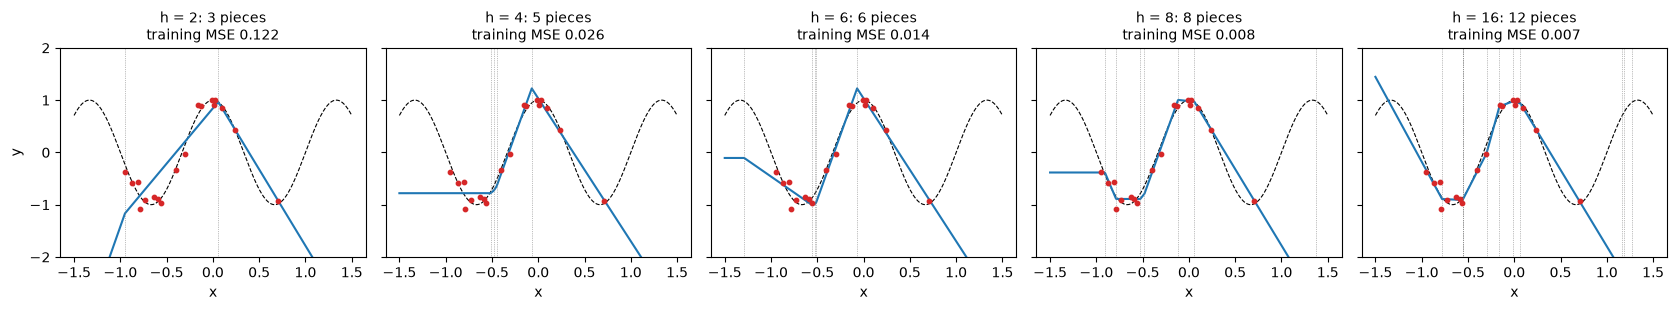

In [13]:
def pieces_and_zero_units(net):
    """Linear pieces of the fit over [-1.5, 1.5], positions of its slope changes there, and the number of
    hidden units that output zero for every training input."""
    w = net[0].weight.detach().numpy().ravel()
    c = net[0].bias.detach().numpy()
    v = net[2].weight.detach().numpy().ravel()
    slope_changes = -c / np.where(w == 0, 1e-12, w)
    # a unit changes the slope of the fit only where its input crosses zero inside the plotted range
    # and its output weight is not zero
    visible = (slope_changes > -1.5) & (slope_changes < 1.5) & (np.abs(v * w) > 1e-4)
    zero_units = np.maximum(0, np.outer(X_train.ravel(), w) + c).max(axis=0) == 0
    return int(visible.sum()) + 1, np.sort(slope_changes[visible]), int(zero_units.sum())


widths = [2, 4, 6, 8, 16]
fig, axes = plt.subplots(1, len(widths), figsize=(3.2 * len(widths) + 1, 3.2), sharey=True)
for ax, h in zip(axes, widths):
    net = fit_relu_layer(h, seed=121)
    pieces, slope_changes, zero_units = pieces_and_zero_units(net)
    mse = np.mean((predict(net, X_train) - y_train.ravel())**2)
    print(f"h = {h:2d}: training MSE {mse:.3f}, {pieces} pieces, slope changes at {np.round(slope_changes, 2)}, "
          f"{zero_units} units zero on all training inputs")
    ax.plot(x_fine, true_func(x_fine), "k--", lw=0.8)
    ax.plot(x_fine, predict(net, x_fine), "tab:blue", lw=1.5)
    ax.scatter(X_train, y_train, c="tab:red", s=10, zorder=3)
    for x_change in slope_changes:
        ax.axvline(x_change, color="gray", lw=0.5, ls=":")
    ax.set_ylim(-2, 2)
    ax.set_title(f"h = {h}: {pieces} pieces\ntraining MSE {mse:.3f}", fontsize=10)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

The dotted vertical lines mark where each unit changes the slope of the fit.

**(a)** At most $h + 1$ pieces. Each unit $\max(0, w_j x + c_j)$ is linear except at $x = -c_j / w_j$, where its slope changes. A weighted sum of $h$ such functions plus a constant can change slope only at these $h$ points, which divide the real line into at most $h + 1$ intervals. The fit has fewer pieces when two of these points coincide, when a point lies outside the plotted range, when a unit outputs zero for every input in the range, or when its output weight $v_j$ is zero.

**(b)** The fit has three pieces, the most that two units can give. The slope changes at $x = -0.95$ and $x = 0.06$: the fit rises steeply to the left of $x = -0.95$, rises more slowly up to the peak at $x = 0.06$, and then falls. The W goes down, up, down, and up again, so it needs four pieces. With three, the fit cannot also go down into the left valley, and the training MSE is 0.122.

**(c)** With $h = 6$ the fit follows the W (training MSE 0.014), and with $h = 8$ its error is at the noise level (0.008, against a noise variance of 0.01).

The W needs only three slope changes, near $x = -0.7$, $0$, and $0.7$, so in principle three or four units are enough. Gradient descent does not put them there. With $h = 4$, three of the four slope changes end up within 0.07 of each other, at $x = -0.52$, $-0.48$, and $-0.45$, so together they act as a single corner, and the fit has a flat floor instead of a left valley (training MSE 0.026). With $h = 6$, three slope changes again end up close together near $x = -0.5$, one lies at $x = -1.29$, outside the data, and one unit outputs zero for every training input. Each unit starts where its random initial weights put it and moves from there, and a unit that outputs zero for every training input has gradient zero and never changes again, as in Exercise 3(d). Extra units make it more likely that enough slope changes end up where the data need them.